<a href="https://colab.research.google.com/github/iwulcho/Neural-Network/blob/main/MCS306_Lab5_Punsalan_Delos_Reyes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MCS 306 - Introduction to Artificial Intelligence
## Guided Laboratory Activity: Artificial Neural Networks

**Mode:** Pair programming  
**Style:** Guided fill-in-the-blanks Python coding  
**Levels:** Easy -> Medium -> Hard -> Final pet-photo demonstration  
**Recommended duration:** 4-5 hours across two laboratory sessions (network speed and GPU availability vary)  
**Platform:** Google Colab recommended; Kaggle Notebooks also supported  
**Submission:** One completed `.ipynb` per pair with visible outputs, written explanations, and a test of an uploaded pet picture

### Why this activity is guided
You have practiced conventional machine-learning algorithms. This time you will **build and train neural networks**, inspect what their learning curves reveal, and apply a **pretrained convolutional neural network** to real animal pictures. Important code statements are deliberately incomplete. Complete only the numbered `FILL` areas unless a task directs otherwise.

**Important:** Dataset download and image-file handling are provided so the time is spent on **designing models, splitting data, preventing leakage, training, evaluating, and predicting**, rather than on setup. The finished code must be understood, not just copied.

## Pair-programming roles

- The **Driver** writes and executes code; the **Navigator** explains the purpose, predicts the outcome, and checks errors.
- Switch roles at the beginning of each level and during the final photo demonstration.
- Both partners must be able to explain **one code decision and one finding from each level**.
- Keep the original `FILL` comments intact so the instructor can identify completed work.

In [27]:
# PROVIDED - change only the values in this information card.
PAIR = {
    "Partner 1": "PUNSALAN, MARK LOUIE",
    "Partner 2": "DELOS REYES, ARJAY HOWARD",
    "Section": "BSM CS 3A",
}
PAIR

{'Partner 1': 'PUNSALAN, MARK LOUIE',
 'Partner 2': 'DELOS REYES, ARJAY HOWARD',
 'Section': 'BSM CS 3A'}

## Learning outcomes

By the end of this exercise, students should be able to:

1. Describe a neuron, hidden layer, activation function, loss function, and training epoch.
2. Build a multilayer perceptron (MLP) for **multiclass classification** with a Kaggle CSV dataset.
3. Separate **training, validation, and test** samples, and standardize tabular inputs without data leakage.
4. Train a neural network; analyze learning curves, overfitting, and the effect of dropout.
5. Compare a neural network with a conventional baseline using classification metrics.
6. Formulate **dog versus not dog** as binary image classification from a second Kaggle dataset.
7. Use **transfer learning**, an ImageNet-pretrained MobileNetV2 backbone, and a sigmoid output.
8. Classify a **new uploaded photo** of a dog or another pet, and discuss why predictions can be wrong.

| Level | Dataset / application | Architecture | Main output |
|---|---|---|---|
| Easy | Mobile Price Classification (Kaggle) | Feedforward MLP | One of four price ranges |
| Medium | Same mobile dataset | MLP with dropout | Comparison, learning curves, final test |
| Hard | Animals-10 (Kaggle) | MobileNetV2 + binary neural-network head | Dog / not dog |
| Final | Student's uploaded pet photo | Trained image classifier | Image, label, and model dog score |

## Kaggle datasets, setup, and responsible use

**Dataset A - Mobile Price Classification:**
[Kaggle dataset](https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification), creator Abhishek Sharma. Use **`train.csv`**, which contains numeric phone specifications and a labeled `price_range` column with values 0-3. **Do not** use Kaggle's `test.csv` as a labeled test set; it does not provide the same training labels.

**Dataset B - Animals-10:**
[Kaggle dataset](https://www.kaggle.com/datasets/alessiocorrado99/animals10), creator Corrado Alessio. This public dataset contains roughly 26-28 thousand images across 10 categories. Its folder names are in Italian: `cane` = dog, `gatto` = cat, etc. **Positive class:** dog (`1`). **Negative class:** the nine other included animal categories (`0`). This is more general than cat-versus-dog, but it **does not cover every possible non-dog object**.

**Requirements:** Python 3.10+, TensorFlow-backed Keras 3, pandas, NumPy, scikit-learn, matplotlib, Pillow, and `kagglehub`. For image training, select a GPU runtime when one is available. **Internet access is needed** for Kaggle files and the first download of pretrained MobileNetV2 weights. Animals-10 is approximately **614 MB**, so allow for a substantial first download.

**Colab:** Runtime -> Change runtime type -> T4 GPU (if available). Run cells from top to bottom.  
**Kaggle:** Turn on a GPU accelerator and Internet access as permitted. `kagglehub` automatically attaches public datasets in Kaggle Notebooks.  
**Privacy:** Upload only photos you own or have permission to use. Do not publish a public notebook showing private pet/household photos without consent. Remove uploaded photos and clear outputs before public sharing.

## Five-minute neural-network primer

A single artificial neuron computes a weighted sum followed by a nonlinear activation:

$$z = w_1x_1 + w_2x_2 + \cdots + w_dx_d + b, \qquad a = f(z).$$

- **Dense (fully connected) layer:** each output neuron reads the previous layer's features.
- **ReLU** `max(0, z)`: a common hidden-layer activation.
- **Softmax:** converts four output scores into four class scores that sum to one (mobile price categories).
- **Sigmoid:** gives one score between 0 and 1 (dog versus not dog).
- **Loss function:** measures the model's error. `sparse_categorical_crossentropy` is for integer-labeled multiclass classification; `binary_crossentropy` is for binary classification with a sigmoid output.
- **Epoch:** one pass through the training set; **batch:** a subset processed before a weight update.
- **Validation data:** helps choose architectures and avoid overfitting; **test data:** is reserved until model selection is finished.
- **Transfer learning:** reuse features extracted by a network trained on a much larger dataset; train a small, new classification head for our task.

**Think first:** Why is `price_range` a four-class problem, while `is_dog` is a two-class problem?

## Setup - run these provided cells first

The installation cell updates `kagglehub` and the upload-widget dependency. **Keras/TensorFlow are expected to be provided by Colab or Kaggle.** Avoid changing the backend after importing Keras. If `keras` import fails, switch to one of the recommended cloud runtimes.

In [28]:
# PROVIDED - install missing dataset and upload tools.
# In Colab or Kaggle Notebook this may finish without installing anything new.
%pip install -q "kagglehub>=1.0.3" "ipywidgets>=8.0"

In [29]:
# PROVIDED - environment and imports
import io
import os
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, clear_output

import kagglehub
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, precision_score, recall_score,
)

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
keras.utils.set_random_seed(RANDOM_STATE)
print("Keras version:", keras.__version__)
print("Keras backend:", keras.backend.backend())
print("Ready. Random seed:", RANDOM_STATE)

Keras version: 3.13.2
Keras backend: tensorflow
Ready. Random seed: 42


# LEVEL 1 - EASY (30 points)
## Application A: Predict a mobile phone's price range with a feedforward neural network

**Driver:** Partner 1 | **Navigator:** Partner 2

Each phone has numerical specifications, including RAM, battery power, and screen properties. The goal is to learn one of four labeled price **ranges**, not an exact currency price.

The following two provided cells retrieve the authentic **Kaggle** training CSV and display its structure.

In [30]:
# PROVIDED - obtain Kaggle data (requires first-time network access)
MOBILE_HANDLE = "iabhishekofficial/mobile-price-classification"
try:
    downloaded = Path(kagglehub.dataset_download(MOBILE_HANDLE, path="train.csv"))
except Exception as err:
    raise RuntimeError(
        "Could not download the public Mobile Price dataset. Check Internet access "
        "and Kaggle account permissions (when needed)."
    ) from err
mobile_csv = downloaded if downloaded.is_file() else next(downloaded.rglob("train.csv"), None)
if mobile_csv is None or not mobile_csv.exists():
    raise FileNotFoundError(f"train.csv not found in {downloaded}")
mobile_df = pd.read_csv(mobile_csv)
print("Kaggle source:", MOBILE_HANDLE)
print("Loaded:", mobile_csv)
print("Table dimensions:", mobile_df.shape)

Using Colab cache for faster access to the 'mobile-price-classification' dataset.
Kaggle source: iabhishekofficial/mobile-price-classification
Loaded: /kaggle/input/mobile-price-classification/train.csv
Table dimensions: (2000, 21)


In [31]:
# PROVIDED - inspect the records, target balance, and missing values
display(mobile_df.head(4))
print("Columns:", list(mobile_df.columns))
print("Missing values:", int(mobile_df.isna().sum().sum()))
print("Target counts:\n", mobile_df["price_range"].value_counts().sort_index())

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2


Columns: ['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g', 'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g', 'touch_screen', 'wifi', 'price_range']
Missing values: 0
Target counts:
 price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64


### E1 - Identify features and labels (5 points)

**Task:** Fill the target column. Construct **X** from specifications only and **y** from the known category. Check that `price_range` is **not in X**.

**Guide:** The label is the answer to be predicted, so including it as an input would let the neural network see the answer during training.

In [32]:
# STUDENT CODE - E1
# FILL 1: target-column name
target_column = "price_range"

X_mobile = mobile_df.drop(columns=[target_column]).copy()
y_mobile = mobile_df[target_column].astype("int32").copy()
print("Features shape:", X_mobile.shape)
print("Targets shape:", y_mobile.shape)
print("Output labels:", sorted(y_mobile.unique()))

Features shape: (2000, 20)
Targets shape: (2000,)
Output labels: [np.int32(0), np.int32(1), np.int32(2), np.int32(3)]


### E2 - Create train, validation, and test sets (5 points)

**Task:** Split the data into **60% training, 20% validation, and 20% testing**. The first split sets aside 20% test data; the next splits the remaining 80% so its validation part is 25% (i.e., 20% of the original dataset).

**Guide:** Use `stratify=` with the relevant **label vector** each time; `random_state` keeps results reproducible. Do not tune against test labels.

In [33]:
# STUDENT CODE - E2
X_dev, X_test, y_dev, y_test = train_test_split(
    X_mobile, y_mobile,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_mobile,  # FILL 1
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_dev,  # FILL 2
)
print("Train:", len(X_train), "Validation:", len(X_val), "Test:", len(X_test))
print("Train-label percentages:\n", y_train.value_counts(normalize=True).sort_index().round(3))

Train: 1200 Validation: 400 Test: 400
Train-label percentages:
 price_range
0    0.25
1    0.25
2    0.25
3    0.25
Name: proportion, dtype: float64


### E3 - Standardize without data leakage (6 points)

**Task:** Fit `StandardScaler` **on training inputs only**, then reuse the same scaler on validation and test inputs. Different phone specifications have very different units and magnitudes.

**Guide:** `.fit_transform()` estimates training-set means/variances; `.transform()` applies those saved values to new observations. The scaler must never use validation or test data to estimate its parameters.

In [34]:
# STUDENT CODE - E3
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # FILL 1
X_val_scaled = scaler.transform(X_val)         # FILL 2
X_test_scaled = scaler.transform(X_test)       # FILL 3

print("Scaled training shape:", X_train_scaled.shape)
print("Mean of first 3 training columns:", np.round(X_train_scaled.mean(axis=0)[:3], 3))

Scaled training shape: (1200, 20)
Mean of first 3 training columns: [-0. -0.  0.]


### E4 - Build and compile a multiclass MLP (8 points)

**Task:** Create a small feedforward network with **32 neurons** in the first hidden layer and **16 neurons** in the second; both use `relu`. Use **four output neurons** with the correct multiclass activation, Adam learning rate `0.001`, and the loss appropriate for **integer class labels**.

**Guide:** `keras.Sequential`, `layers.Dense`, and `keras.optimizers.Adam`. The four output class scores should sum to about one for any observation.

In [35]:
# STUDENT CODE - E4
n_features = X_train_scaled.shape[1]
n_classes = len(np.unique(y_train))
mobile_ann = keras.Sequential([
    keras.Input(shape=(n_features,)),
    layers.Dense(32, activation="relu"),  # FILL 1: neurons
    layers.Dense(16, activation="relu"),
    layers.Dense(n_classes, activation="softmax"),  # FILL 2: activation
], name="mobile_price_mlp")

mobile_ann.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),  # FILL 3
    loss="sparse_categorical_crossentropy",  # FILL 4
    metrics=["accuracy"],
)
mobile_ann.summary()

Model: "mobile_price_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,268 (4.95 KB)

 Trainable params: 1,268 (4.95 KB)

 Non-trainable params: 0 (0.00 B)

### E5 - Train the neural network (3 points)

**Task:** Train on **training data**, watch **validation data**, and use the provided early-stopping callback. Set `epochs=30` as an upper bound; training may stop earlier.

**Guide:** The first two arguments to `.fit()` are the feature matrix and labels. Do **not** pass `X_test_scaled` here.

In [36]:
# STUDENT CODE - E5
history_ann = mobile_ann.fit(
    X_train_scaled,  # FILL 1: training X
    y_train,  # FILL 2: training y
    validation_data=(X_val_scaled, y_val),  # FILL 3/4
    epochs=30,
    batch_size=32,
    verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )],
)
print("Completed epochs:", len(history_ann.history["loss"]))
print("Best validation accuracy:", round(max(history_ann.history["val_accuracy"]), 3))

Completed epochs: 30
Best validation accuracy: 0.91


### E6 - Evaluate on the validation split (3 points)

**Task:** Convert the four network output scores into **predicted class indices** using `argmax`; compute **accuracy** and **macro-F1** against the validation labels.

Accuracy is the fraction of correct predictions. Macro-F1 averages the per-class F1 scores equally:

$$F_1 = \frac{2 \cdot \mathrm{precision} \cdot \mathrm{recall}}{\mathrm{precision} + \mathrm{recall}}.$$

In [11]:
# STUDENT CODE - E6
val_probabilities = mobile_ann.predict(X_val_scaled, verbose=0)  # FILL 1
val_predictions = np.argmax(val_probabilities, axis=1)                    # FILL 2
val_accuracy = accuracy_score(y_val, val_predictions)             # FILL 3/4
val_f1 = f1_score(y_val, val_predictions, average="macro")          # FILL 5/6
print(f"Validation accuracy: {val_accuracy:.3f}")
print(f"Validation macro-F1: {val_f1:.3f}")
print("Sample prediction scores (sum):", round(float(val_probabilities[0].sum()), 3))

Validation accuracy: 0.910
Validation macro-F1: 0.909
Sample prediction scores (sum): 1.0


### Easy-level reflection - answer as a pair

1. What is the difference between a hidden layer and an output layer?
2. Why did we choose **softmax** and **sparse categorical crossentropy** for the price categories?
3. What mistake would occur if `scaler.fit_transform()` were called on the full dataset before splitting?
4. Compare accuracy and macro-F1 on validation. What do these values measure that a training loss does not?

**Pair answers**

1. Hidden layers extract learned patterns from input phone specs (like RAM and battery) while the output layer uses these patterns to generate the final scores for the four price ranges.

2. We chose softmax to convert the output scores into probabilities summing to 1 to identify the most likely price range. Sparse categorical crossentropy is used because our labels are mutually exclusive integers (0 to 3) removing the need for one-hot encoding.

3. Scaling the entire dataset causes data leakage by allowing validation and test statistics to influence training and artificially inflate performance scores. Prevent this by fitting the scaler exclusively on the training data.

4. Accuracy (percentage of correct predictions) and macro-F1 (average F1 across all ranges equally) evaluate true model performance on unseen data. Training loss only reflects error on seen data and cannot indicate how well the model generalizes to new phones.


# LEVEL 2 - MEDIUM (25 points)
## Improve and compare your feedforward network

**Driver:** Partner 2 | **Navigator:** Partner 1

An effective neural network is not just one that can be trained; we must **understand how it generalizes**. We will inspect training curves, add dropout to a second model, compare with a conventional classifier, then evaluate the selected neural network on the **held-out test set exactly once**.

### M1 - Plot and interpret learning curves (5 points)

**Task:** Plot **training loss** and **validation loss** as a function of epoch. Look for a widening gap that suggests overfitting. Describe what you observe (a gap is not guaranteed).

**Guide:** Keras stores its metrics in `history_ann.history`, including `"loss"` and `"val_loss"`.

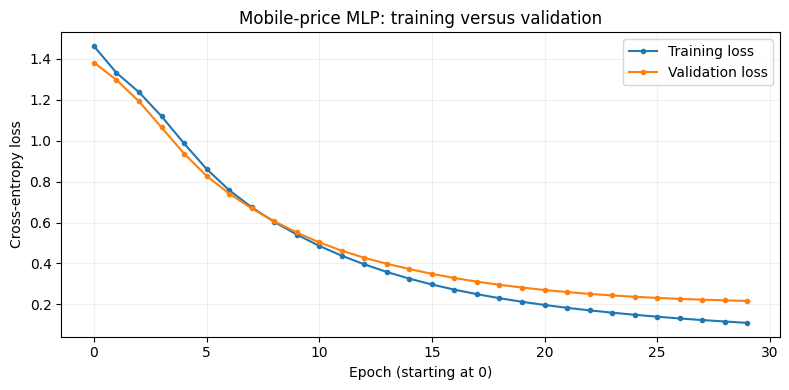

In [12]:
# STUDENT CODE - M1
training_losses = history_ann.history["loss"]  # FILL 1
validation_losses = history_ann.history["val_loss"] # FILL 2

plt.figure(figsize=(8, 4))
plt.plot(training_losses, marker="o", ms=3, label="Training loss")
plt.plot(validation_losses, marker="o", ms=3, label="Validation loss")
plt.xlabel("Epoch (starting at 0)")
plt.ylabel("Cross-entropy loss")
plt.title("Mobile-price MLP: training versus validation")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### M2 - Train a second MLP with dropout (10 points)

**Task:** Build a second network with `64 -> Dropout(0.20) -> 32 -> 4` neurons, ReLU for hidden layers, and softmax output. Use Adam learning rate **0.0005**. Keep the **same dataset splits and scaler** for a fair comparison.

**Guide:** Dropout randomly deactivates a fraction of hidden outputs **during training**. It can reduce overfitting, but it does not guarantee higher accuracy. The `fit()` call should use the **training** and **validation** sets only.

In [13]:
# STUDENT CODE - M2
tuned_ann = keras.Sequential([
    keras.Input(shape=(n_features,)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.20),           # FILL 1: rate
    layers.Dense(32, activation="relu"),  # FILL 2
    layers.Dense(n_classes, activation="softmax"),
], name="dropout_mobile_mlp")
tuned_ann.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),  # FILL 3
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
history_tuned = tuned_ann.fit(
    X_train_scaled, y_train,  # FILL 4/5: training X/y
    validation_data=(X_val_scaled, y_val), # FILL 6/7
    epochs=35, batch_size=32, verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )],
)
print("Tuned epochs:", len(history_tuned.history["loss"]))

Tuned epochs: 35


### M3 - Compare validation results with a non-neural baseline (5 points)

**Task:** Fit `LogisticRegression` on the **same scaled training set**. Compare validation macro-F1 for (1) original MLP, (2) dropout MLP, and (3) logistic regression. Choose the **better of the two neural networks** from validation macro-F1 for the final neural-network test; report if the conventional baseline performs better.

**Guide:** Use `.predict()` for logistic regression, but use `argmax` on a Keras model's softmax output. A simpler model sometimes wins on small, structured datasets.

In [14]:
# STUDENT CODE - M3
baseline = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
baseline.fit(X_train_scaled, y_train)    # FILL 1/2
baseline_val_pred = baseline.predict(X_val_scaled) # FILL 3

tuned_val_prob = tuned_ann.predict(X_val_scaled, verbose=0) # FILL 4
tuned_val_pred = np.argmax(tuned_val_prob, axis=1)
tuned_val_f1 = f1_score(y_val, tuned_val_pred, average="macro")
baseline_val_f1 = f1_score(y_val, baseline_val_pred, average="macro")

comparison = pd.DataFrame({
    "Model": ["Original MLP", "Dropout MLP", "Logistic regression"],
    "Validation macro-F1": [val_f1, tuned_val_f1, baseline_val_f1],
})
display(comparison.round(3))
best_nn = tuned_ann if tuned_val_f1 > val_f1 else mobile_ann # FILL 5: choose better *neural network* by validation F1
print("Selected neural network:", best_nn.name)

,Model,Validation macro-F1
0,Original MLP,0.909
1,Dropout MLP,0.922
2,Logistic regression,0.967


Selected neural network: dropout_mobile_mlp


### M4 - Final multiclass test evaluation (5 points)

**Task:** Now that the neural-network choice is fixed, evaluate the **selected model** once on the held-out test set. Show accuracy, macro-F1, per-class precision/recall, and a confusion matrix.

**Guide:** Only the frozen choice `best_nn` sees the final test set. Do **not** return to the previous level to tune the model based on test results.

Test accuracy: 0.915
Test macro-F1: 0.915
              precision    recall  f1-score   support

           0       0.93      0.95      0.94       100
           1       0.90      0.86      0.88       100
           2       0.90      0.88      0.89       100
           3       0.93      0.97      0.95       100

    accuracy                           0.92       400
   macro avg       0.91      0.92      0.91       400
weighted avg       0.91      0.92      0.91       400



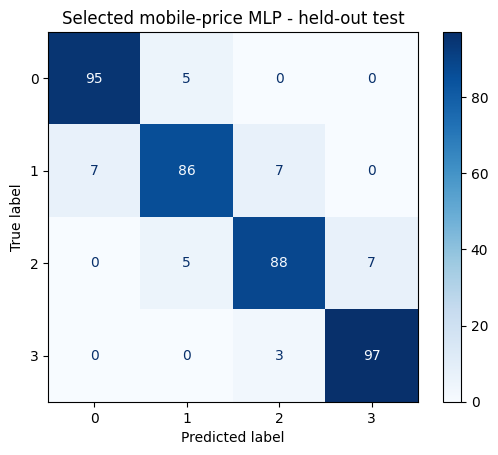

In [15]:
# STUDENT CODE - M4
final_prob = best_nn.predict(X_test_scaled, verbose=0) # FILL 1
final_pred = np.argmax(final_prob, axis=1)
print("Test accuracy:", round(accuracy_score(y_test, final_pred), 3)) # FILL 2
print("Test macro-F1:", round(f1_score(y_test, final_pred, average="macro"), 3))
print(classification_report(y_test, final_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, cmap="Blues")
plt.title("Selected mobile-price MLP - held-out test")
plt.show()

### Medium-level reflection - answer as a pair

1. Did the first MLP show a training/validation loss gap? Refer to the plot, not to a guess.
2. Did adding dropout improve validation macro-F1? Why might dropout help in some datasets but not others?
3. Which neural network did you select, and why is **validation performance** the correct basis for that decision?
4. Did logistic regression outperform the neural networks? What does that suggest about architecture complexity?
5. Why should the test set not be used repeatedly to choose a learning rate, number of epochs, or dropout rate?

**Pair answers**

1. Yes. The training and validation losses initially decreased together, but a gap developed in later epochs. This suggests that the model started to overfit the training data.

2. Yes. Dropout improved the macro-F1 from 0.909 to 0.922 by reducing the model's reliance on specific neurons. However, its effectiveness depends on the dataset and the degree of overfitting.

3. We selected the dropout MLP because it achieved a higher validation macro-F1 of 0.922 compared to 0.909. Validation performance is appropriate for model selection because it evaluates generalization without using the test set.

4. Yes. Logistic regression achieved a validation macro-F1 of 0.967, outperforming both neural networks. This shows that simpler models can perform better than more complex architectures, depending on the dataset.

5. Repeatedly using the test set for tuning can introduce bias and make the final evaluation unreliable. The validation set should be used for adjusting model parameters, while the test set should only be used for final evaluation.


# LEVEL 3 - HARD (40 points)
## Application B: Train a neural network that identifies dogs in animal pictures

**Driver:** Partner 1 | **Navigator:** Partner 2

**Real-world situation:** Your classmates want a simple application: upload a photo of a pet and ask **"Is this a dog?"** Unlike phone specifications, images contain spatial information. We will use a **convolutional neural network (CNN)** to extract features.

**Binary target:** `dog = 1`, `not dog = 0`. The *not dog* class includes the nine **other species in Animals-10**, not arbitrary everyday photographs. To avoid severe imbalance, use **360 dog photos** and **40 photos from each of nine other species** (also 360).

**Important distinction:** We are **not** classifying the exact species of every animal; one sigmoid output answers only whether the image looks like the trained dog class.

### Data preparation (provided)

The next cell downloads the image dataset from **Kaggle**, scans its folders, checks candidate image files, and selects a small, reproducible, **balanced** learning subset. The validation and test images are selected separately **after** sampling. Sampling the same image twice is not intended. If pretrained weights cannot download later, turn on Internet access or use Colab.

In [16]:
# PROVIDED - obtain the Kaggle Animals-10 image dataset
ANIMAL_HANDLE = "alessiocorrado99/animals10"
try:
    animal_download_root = Path(kagglehub.dataset_download(ANIMAL_HANDLE))
except Exception as err:
    raise RuntimeError(
        "Animals-10 download failed. It is a large public Kaggle dataset; "
        "check Internet access, disk allowance, and Kaggle permissions."
    ) from err

animal_root = animal_download_root / "raw-img"
if not animal_root.is_dir():
    found = [p for p in animal_download_root.rglob("raw-img") if p.is_dir()]
    if not found:
        raise FileNotFoundError(f"Animals-10 raw-img directory not found under {animal_download_root}")
    animal_root = found[0]

animal_names = {
    "cane": "dog", "gatto": "cat", "cavallo": "horse",
    "ragno": "spider", "farfalla": "butterfly", "gallina": "chicken",
    "pecora": "sheep", "mucca": "cow", "scoiattolo": "squirrel",
    "elefante": "elephant",
}
image_sources = {}
for folder, english in animal_names.items():
    folder_path = animal_root / folder
    if not folder_path.is_dir():
        raise FileNotFoundError(f"Expected {english} folder missing: {folder_path}")
    image_sources[folder] = sorted(
        p for p in folder_path.iterdir()
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )
print("Kaggle source:", ANIMAL_HANDLE)
print("Found image files per species:")
for folder, candidates in image_sources.items():
    print(f"  {animal_names[folder]:10}: {len(candidates)}")

Using Colab cache for faster access to the 'animals10' dataset.
Kaggle source: alessiocorrado99/animals10
Found image files per species:
  dog       : 4863
  cat       : 1668
  horse     : 2623
  spider    : 4821
  butterfly : 2112
  chicken   : 3098
  sheep     : 1820
  cow       : 1866
  squirrel  : 1862
  elephant  : 1446


### H1 - Construct a balanced binary dataset (8 points)

**Task:** Keep the provided sampler; **fill the binary target** for each photograph: `1` when `species == "cane"` and `0` otherwise. Then confirm the sample contains **360 dogs and 360 non-dogs**. Examine the count per species to see how the negative class is composed.

**Why balance?** With all 10 species in their original amounts, a model could lean toward predicting *not dog* and still appear accurate. A balanced sample makes the initial exercise easier to interpret, although real-world deployment may have a different class ratio.

In [17]:
# STUDENT CODE - H1
# PROVIDED: sample a fixed amount per species and reject unreadable files.
image_rows = []
rng = np.random.default_rng(RANDOM_STATE)
for species, candidates in image_sources.items():
    desired = 360 if species == "cane" else 40
    order = rng.permutation(len(candidates))
    accepted = 0
    for j in order:
        candidate = candidates[int(j)]
        try:
            with Image.open(candidate) as image:
                image.verify()
        except (OSError, ValueError):
            continue
        image_rows.append({"filepath": str(candidate), "species": species})
        accepted += 1
        if accepted == desired:
            break
    if accepted < desired:
        raise ValueError(f"Not enough readable files for {species}: {accepted} < {desired}")

animal_df = pd.DataFrame(image_rows).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

# FILL 1: create integer binary dog labels based on the Italian folder name
animal_df["is_dog"] = (animal_df["species"] == "cane").astype(int)

display(animal_df.head(3))
print("Binary target counts:\n", animal_df["is_dog"].value_counts().sort_index())
print("Animals per species:\n", animal_df["species"].value_counts().sort_index())

,filepath,species,is_dog
0,/kaggle/input/animals10/raw-img/cane/OIP-tu2yk...,cane,1
1,/kaggle/input/animals10/raw-img/cane/OIP-T0pqa...,cane,1
2,/kaggle/input/animals10/raw-img/cane/OIP-6Iv9N...,cane,1


Binary target counts:
 is_dog
0    360
1    360
Name: count, dtype: int64
Animals per species:
 species
cane          360
cavallo        40
elefante       40
farfalla       40
gallina        40
gatto          40
mucca          40
pecora         40
ragno          40
scoiattolo     40
Name: count, dtype: int64


### H2 - Split images without losing species diversity (8 points)

**Task:** Create a **60% training / 20% validation / 20% test** split. Use **species-based stratification**, not just binary-label stratification, so each of the ten animals is represented in every split.

**Guide:** First reserve 40% (`animal_temp`); then split `animal_temp` in half. Training and validation are for model development; the image test set is held out until model choice is fixed.

In [18]:
# STUDENT CODE - H2
animal_train, animal_temp = train_test_split(
    animal_df,
    test_size=0.40,    # FILL 1
    random_state=RANDOM_STATE,
    stratify=animal_df["species"],         # FILL 2
)
animal_val, animal_test = train_test_split(
    animal_temp,
    test_size=0.50,    # FILL 3
    random_state=RANDOM_STATE,
    stratify=animal_temp["species"],         # FILL 4
)
print("Train:", animal_train.shape, "Val:", animal_val.shape, "Test:", animal_test.shape)
print("Test binary proportions:", animal_test["is_dog"].value_counts(normalize=True).round(3).to_dict())

Train: (432, 3) Val: (144, 3) Test: (144, 3)
Test binary proportions: {0: 0.5, 1: 0.5}


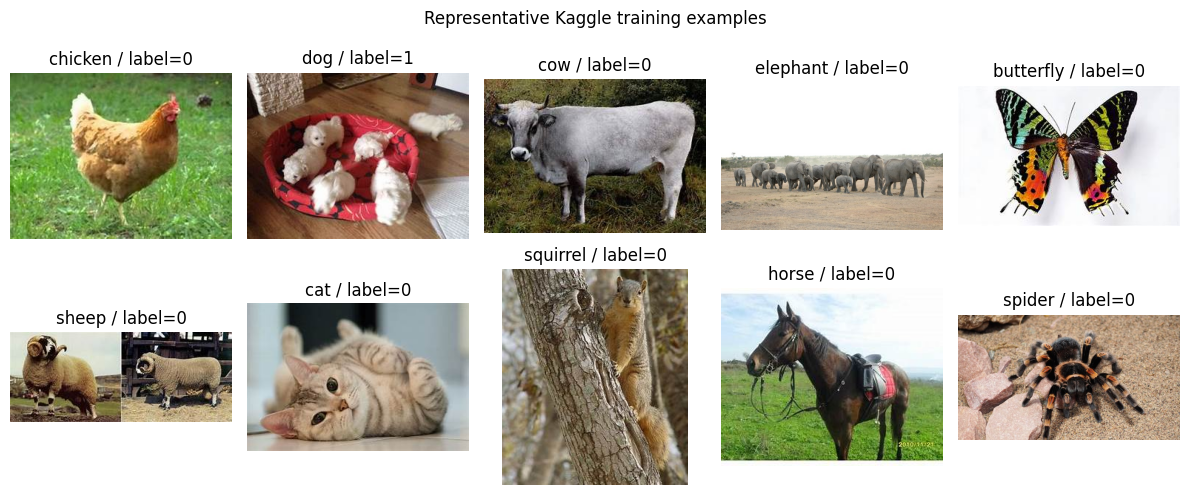

In [19]:
# PROVIDED - visually inspect a few training photos (never inspect test photos for tuning)
chosen = animal_train.groupby("species", group_keys=False).head(1).head(10)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, (_, row) in zip(axes.ravel(), chosen.iterrows()):
    with Image.open(row["filepath"]) as image:
        ax.imshow(ImageOps.exif_transpose(image).convert("RGB"))
    ax.set_title(f"{animal_names[row['species']]} / label={row['is_dog']}")
    ax.axis("off")
plt.suptitle("Representative Kaggle training examples")
plt.tight_layout()
plt.show()

### H3 - Resize images into input tensors (6 points)

**Task:** Define a preprocessing function that opens each file, converts it to **RGB**, resizes it to **160 x 160** pixels, and returns an unsigned 8-bit NumPy array. Then create the training, validation, and test arrays.

**Guide:** A CNN expects a batch of shape `(number_of_images, height, width, 3)`. We will keep pixel values in **0-255** here; the model itself performs MobileNetV2 normalization. **Do not divide them by 255 a second time.**

In [20]:
# STUDENT CODE - H3
IMAGE_SIZE = 160

def image_to_array(filepath):
    with Image.open(filepath) as source:
        corrected = ImageOps.exif_transpose(source)
        rgb = corrected.convert("RGB")  # FILL 1: image mode
        small = rgb.resize((IMAGE_SIZE, IMAGE_SIZE))
        return np.asarray(small, dtype=np.uint8)

# FILL 2/3/4: pass the path column for each split
X_train_img = np.stack([image_to_array(p) for p in animal_train["filepath"]])
X_val_img = np.stack([image_to_array(p) for p in animal_val["filepath"]])
X_test_img = np.stack([image_to_array(p) for p in animal_test["filepath"]])
y_train_img = animal_train["is_dog"].to_numpy(dtype=np.float32)
y_val_img = animal_val["is_dog"].to_numpy(dtype=np.float32)
y_test_img = animal_test["is_dog"].to_numpy(dtype=np.int32)

print("Training images:", X_train_img.shape, X_train_img.dtype)
print("Validation images:", X_val_img.shape)
print("Test images:", X_test_img.shape)

Training images: (432, 160, 160, 3) uint8
Validation images: (144, 160, 160, 3)
Test images: (144, 160, 160, 3)


### H4 - Build a transfer-learning CNN (10 points)

**Task:** We will use a MobileNetV2 feature extractor pretrained on ImageNet. The **convolutional backbone is frozen**, while the small new classification head learns to distinguish our two groups. Complete the final `Dense` layer and its **binary cross-entropy** loss.

**Why not train everything from scratch?** Our lab subset has only 720 images, which is often too small for reliable training of a large CNN from random weights. Transfer learning starts from useful visual features.

**Architecture:** `Input -> RandomFlip -> Rescaling to [-1, 1] -> MobileNetV2 -> GlobalAveragePooling -> Dropout -> Dense(1, sigmoid)`.

**Guide:** Use `units=1`, `activation="sigmoid"`, and `loss="binary_crossentropy"`. If the pretrained weights cannot be fetched, enable Internet and rerun; **do not silently change to random weights** and interpret the output as a trained classifier.

In [21]:
# STUDENT CODE - H4
try:
    backbone = keras.applications.MobileNetV2(
        include_top=False,
        weights="imagenet",
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    )
except Exception as err:
    raise RuntimeError(
        "Could not access pretrained MobileNetV2 weights. Enable the runtime's "
        "Internet access, or use Colab, then retry H4."
    ) from err
backbone.trainable = False  # PROVIDED: frozen pretrained feature extractor

inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
x = layers.RandomFlip("horizontal")(inputs)
x = layers.Rescaling(scale=1.0 / 127.5, offset=-1.0)(x)
x = backbone(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.20)(x)
outputs = layers.Dense(
    1, activation="sigmoid"  # FILL 1/2
)(x)
dog_net = keras.Model(inputs=inputs, outputs=outputs, name="dog_or_not_dog")
dog_net.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",  # FILL 3
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.AUC(name="auc")],
)
dog_net.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "dog_or_not_dog"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### H5 - Train the dog-versus-not-dog network (4 points)

**Task:** Train the small classification head on the **training images** and monitor the **validation images**. The `EarlyStopping` callback stops if validation loss no longer improves for two consecutive epochs and restores the best weights.

**Guide:** Use `X_train_img`, `y_train_img`, `X_val_img`, and `y_val_img`. A GPU is strongly recommended; CPU training may be slow. The pretrained backbone is frozen to keep this activity manageable.

In [22]:
# STUDENT CODE - H5
history_dog = dog_net.fit(
    X_train_img, y_train_img,  # FILL 1/2: image training data
    validation_data=(X_val_img, y_val_img),  # FILL 3/4
    epochs=6,
    batch_size=32,
    verbose=1,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True
    )],
)
print("Dog-model training epochs:", len(history_dog.history["loss"]))

Epoch 1/6
14/14 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.6111 - auc: 0.6613 - loss: 0.6739 - val_accuracy: 0.6875 - val_auc: 0.7497 - val_loss: 0.5904
Epoch 2/6
14/14 ━━━━━━━━━━━━━━━━━━━━ 12s 910ms/step - accuracy: 0.8056 - auc: 0.8863 - loss: 0.4513 - val_accuracy: 0.8194 - val_auc: 0.9109 - val_loss: 0.4329
Epoch 3/6
14/14 ━━━━━━━━━━━━━━━━━━━━ 20s 899ms/step - accuracy: 0.9074 - auc: 0.9681 - loss: 0.3049 - val_accuracy: 0.8819 - val_auc: 0.9567 - val_loss: 0.3397
Epoch 4/6
14/14 ━━━━━━━━━━━━━━━━━━━━ 12s 897ms/step - accuracy: 0.9282 - auc: 0.9786 - loss: 0.2521 - val_accuracy: 0.9028 - val_auc: 0.9733 - val_loss: 0.2845
Epoch 5/6
14/14 ━━━━━━━━━━━━━━━━━━━━ 13s 969ms/step - accuracy: 0.9537 - auc: 0.9898 - loss: 0.2000 - val_accuracy: 0.9167 - val_auc: 0.9809 - val_loss: 0.2481
Epoch 6/6
14/14 ━━━━━━━━━━━━━━━━━━━━ 12s 901ms/step - accuracy: 0.9514 - auc: 0.9897 - loss: 0.1774 - val_accuracy: 0.9167 - val_auc: 0.9836 - val_loss: 0.2242
Dog-model training epochs: 6


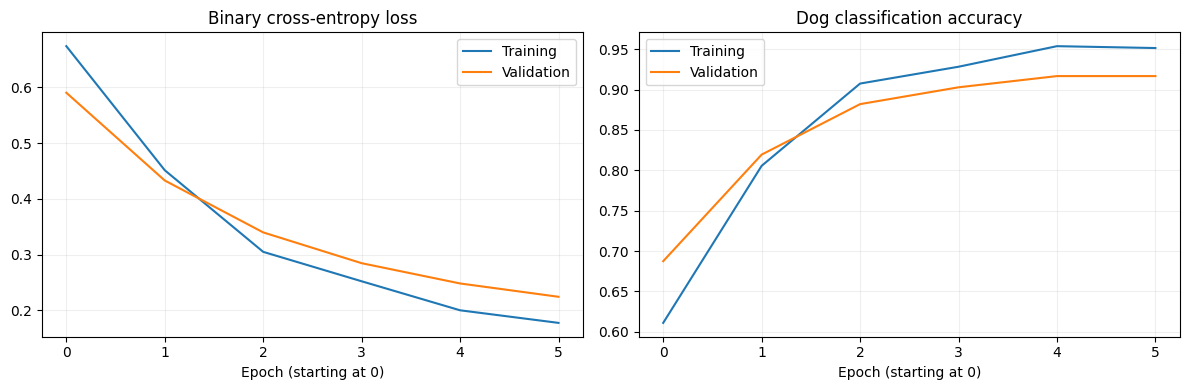

In [23]:
# PROVIDED - examine dog model learning curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_dog.history["loss"], label="Training")
axes[0].plot(history_dog.history["val_loss"], label="Validation")
axes[0].set_title("Binary cross-entropy loss")
axes[1].plot(history_dog.history["accuracy"], label="Training")
axes[1].plot(history_dog.history["val_accuracy"], label="Validation")
axes[1].set_title("Dog classification accuracy")
for ax in axes:
    ax.set_xlabel("Epoch (starting at 0)")
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### H6 - Evaluate dogs and non-dogs on held-out images (4 points)

**Task:** Set a fixed threshold **0.50**, then use the network's sigmoid scores to predict either `0` (*not dog*) or `1` (*dog*) for the **held-out test images**. Report accuracy, precision, recall, F1, and a confusion matrix.

**Guide:** `dog_net.predict()` gives a score. The rule `score >= threshold` converts it to a class. **A score is not a guarantee of correctness or a formally calibrated probability.** A false negative is an actual dog predicted as not dog.

Accuracy: 0.958
Dog-class precision: 0.958
Dog-class recall: 0.958
Dog-class F1: 0.958
              precision    recall  f1-score   support

     Not dog       0.96      0.96      0.96        72
         Dog       0.96      0.96      0.96        72

    accuracy                           0.96       144
   macro avg       0.96      0.96      0.96       144
weighted avg       0.96      0.96      0.96       144



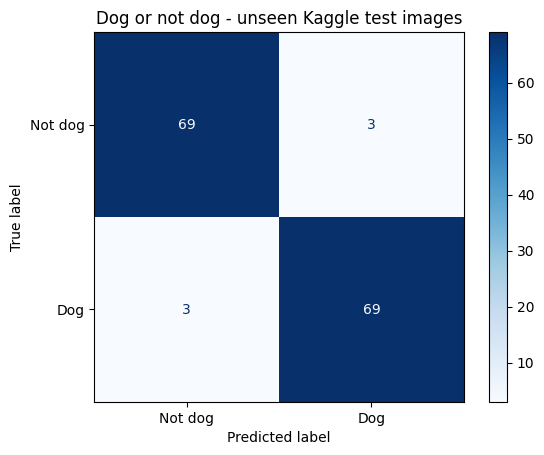

In [24]:
# STUDENT CODE - H6
dog_test_scores = dog_net.predict(X_test_img, verbose=0).ravel() # FILL 1
DOG_THRESHOLD = 0.50  # FILL 2: fixed initial threshold
dog_test_predictions = (dog_test_scores >= DOG_THRESHOLD).astype(int)

print("Accuracy:", round(accuracy_score(y_test_img, dog_test_predictions), 3)) # FILL 3/4
print("Dog-class precision:", round(precision_score(y_test_img, dog_test_predictions, zero_division=0), 3))
print("Dog-class recall:", round(recall_score(y_test_img, dog_test_predictions, zero_division=0), 3))
print("Dog-class F1:", round(f1_score(y_test_img, dog_test_predictions, zero_division=0), 3))
print(classification_report(
    y_test_img, dog_test_predictions,
    target_names=["Not dog", "Dog"], zero_division=0,
))
ConfusionMatrixDisplay.from_predictions(
    y_test_img, dog_test_predictions,
    labels=[0, 1], display_labels=["Not dog", "Dog"], cmap="Blues",
)
plt.title("Dog or not dog - unseen Kaggle test images")
plt.show()

### Hard-level reflection - answer as a pair

1. Why is *dog / not dog* a **binary** task, although the source dataset has 10 folders?
2. Why did we sample an equal number of dog and non-dog photos? Is a balanced classroom dataset always representative of the real world?
3. What benefits does a **convolutional** pretrained backbone provide over flattening every image into a large list of numbers?
4. Explain what `backbone.trainable = False` changes during learning.
5. Identify which confusion-matrix cell represents **dogs mistakenly predicted not dog**. How could you improve detection without tuning on the final test set?
6. Name two images on which this model may fail (e.g., a rabbit, multiple animals, unusual lighting) and explain why.

**Pair answers**

1. The task is binary because the prediction requires only two outcomes: dog (1) or not dog (0). We consolidated the nine non-dog folders into a single "not dog" class and used a sigmoid output layer.

2. We balanced the dataset with 360 dog images and 360 non-dog images to reduce the effect of class imbalance during training. However, a balanced dataset may not represent real-world conditions, where dogs and non-dogs may appear at different frequencies.

3. A pretrained CNN can identify spatial patterns such as edges, textures, and shapes while preserving the image's spatial structure. Unlike a basic flattened input, convolutional layers are designed to learn local visual features, and the pretrained backbone already contains useful features learned from ImageNet.

4. Setting backbone.trainable = False freezes the pretrained backbone's weights, so they are not updated during training. Only the newly added classification layers are trained, reducing the number of trainable parameters.

5. Dogs mistakenly predicted as not dog are False Negatives located in the bottom-left cell (Actual Dog row, Predicted Not Dog column). To improve detection without touching the test set we could lower the decision threshold on the validation set, apply image augmentation, or add more training data.

6. The model might fail on a rabbit because it was not included in the "not dog" training classes and the model hasn't learned its features. It could also fail on images with both a dog and a cat or heavily obscured/blurry dogs due to mixed or degraded visual features.


# FINAL CHALLENGE - UPLOAD A PET PHOTO (5 points)
## "Is this a dog?" - classify an image that was NOT part of Kaggle training

**Switch roles again.** Now use the trained `dog_net` to classify a photo **from your computer**. A dog photo should ideally return *DOG*; a cat, bird, or another non-dog pet should ideally return *NOT DOG*. **Neither result is guaranteed.**

**Photo rules:** Use a `.jpg`, `.jpeg`, or `.png` that you own or have permission to use. One animal clearly visible is easiest, but you are encouraged to experiment with difficult cases. Do not upload sensitive photos to a public notebook.

**Student task:** Complete the three key inference steps below: resize the photo to the same model input size, calculate the model's score, and turn the score into the appropriate label using the already chosen threshold. **Keep pixel values in 0-255** because the model contains its own rescaling layer.

In [25]:
# STUDENT CODE - FINAL: the upload interface below calls this function.
def classify_pet_photo(image_bytes, filename="uploaded_pet_photo"):
    """Display a user-uploaded picture and the trained dog/not-dog result."""
    try:
        pil_photo = ImageOps.exif_transpose(Image.open(io.BytesIO(image_bytes))).convert("RGB")
    except (OSError, ValueError) as err:
        print("That file could not be opened as a picture:", err)
        return

    # FILL 1: resize with IMAGE_SIZE, and convert to a NumPy array
    resized_photo = np.asarray(pil_photo.resize((IMAGE_SIZE, IMAGE_SIZE)), dtype=np.uint8)
    # FILL 2: predict on a batch containing just this one image
    dog_score = float(dog_net.predict(resized_photo[np.newaxis, ...], verbose=0).ravel()[0])
    # FILL 3: apply DOG_THRESHOLD to choose exactly DOG or NOT DOG
    decision = "DOG" if dog_score >= DOG_THRESHOLD else "NOT DOG"

    plt.figure(figsize=(5, 5))
    plt.imshow(pil_photo)
    plt.axis("off")
    plt.title(f"{filename}: {decision}")
    plt.tight_layout()
    plt.show()
    print("Prediction:", decision)
    print(f"Dog-class model score: {dog_score:.1%}  (decision threshold: {DOG_THRESHOLD:.0%})")
    print("Reminder: The score is a model estimate, not proof or a calibrated probability.")

### Upload and classify a photo - run this cell last

**Google Colab:** a local file chooser opens when you run the cell. Select an image of your pet.  
**Kaggle / ordinary Jupyter:** use the displayed **Upload pet photo** widget, then click **Classify uploaded photo**. This reads photo bytes directly; you do not need to publish them as a dataset. If your notebook frontend blocks upload widgets, use the optional path-based fallback after this cell.

**Student check:** Before clicking, confirm that the inference function above has been completed and the H4-H5 model has been trained.

Saving cooper.jpg to cooper.jpg


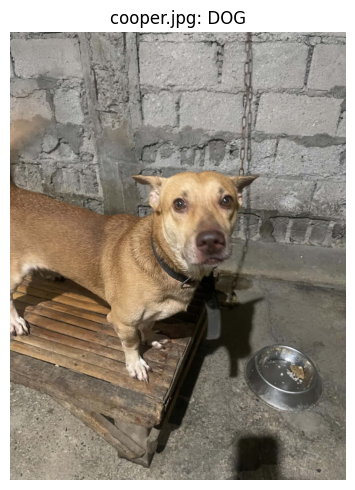

Prediction: DOG
Dog-class model score: 97.7%  (decision threshold: 50%)
Reminder: The score is a model estimate, not proof or a calibrated probability.


In [26]:
# PROVIDED - cross-platform upload interface. Run after completing FINAL.
def _read_widget_upload(value):
    """Handle ipywidgets 7 (dict) and 8 (tuple) upload representations."""
    if not value:
        return None
    if isinstance(value, dict):
        filename, record = next(iter(value.items()))
        return filename, bytes(record["content"])
    entry = value[0]
    return entry.get("name", "uploaded_pet_photo"), bytes(entry["content"])

try:
    from google.colab import files as colab_files
except ImportError:
    import ipywidgets as widgets
    photo_uploader = widgets.FileUpload(
        accept=".jpg,.jpeg,.png", multiple=False,
        description="Upload pet photo"
    )
    classify_button = widgets.Button(
        description="Classify uploaded photo", button_style="primary"
    )
    upload_output = widgets.Output()

    def _on_classify_click(_):
        with upload_output:
            clear_output(wait=True)
            chosen = _read_widget_upload(photo_uploader.value)
            if chosen is None:
                print("Choose a JPG or PNG image first, then click Classify.")
                return
            filename, content = chosen
            classify_pet_photo(content, filename=filename)

    classify_button.on_click(_on_classify_click)
    display(photo_uploader, classify_button, upload_output)
else:
    uploaded_photos = colab_files.upload()
    if not uploaded_photos:
        print("No image uploaded. Run this cell again and select a photo.")
    else:
        for filename, content in uploaded_photos.items():
            classify_pet_photo(content, filename=filename)

In [ ]:
# PROVIDED - optional Kaggle/Jupyter fallback if the upload widget cannot be used.
# 1) Upload a pet image as a private Kaggle dataset, then attach it to your notebook.
# 2) Replace the text below with the real path shown in Kaggle's Input panel.
# 3) Uncomment the final three lines and run them.
# PET_IMAGE_PATH = "/kaggle/input/my-private-pet-picture/pet.jpg"
# with open(PET_IMAGE_PATH, "rb") as f:
#     classify_pet_photo(f.read(), filename=Path(PET_IMAGE_PATH).name)

### Final upload reflection - complete this after a prediction

**The uploaded image was:** dog / cat / other pet (specify)  

**Filename or neutral description:** Dog (cooper.jpg)

**Actual label (based on your knowledge):** Dog

**Model prediction:** DOG  

**Dog-class model score:** 97.7%

**Did the result match the actual label?** Yes. The model correctly classified the uploaded image as DOG, with a confidence score of 97.7%

**If correct or incorrect, what visual factors may have affected the result?** The recognizable physical features of the dog may have helped the model identify it correctly. The image provided sufficient visual information for classification.  

**One limitation of this two-class animal classifier:** The model was trained using only ten animal categories from Animals-10. It may misclassify unfamiliar animals or objects that were not represented in its training data.

If you do not have a pet, use a permitted image of an animal and state the source. Do not claim the network is universally reliable after one successful photo.

## Submission checklist

- [x] Both partner names and the section are filled in.
- [x] Every numbered `FILL` statement has been replaced by working code.
- [x] The two datasets are actually loaded from **Kaggle** (not substituted with built-in datasets).
- [x] Every level executes top to bottom in the cloud notebook environment.
- [x] Phone validation and final test metrics, learning curves, and confusion matrix are visible.
- [x] Dog-model test metrics and training plots are visible.
- [x] At least one **uploaded personal/permitted animal photo** was classified with its output visible.
- [x] Easy, Medium, Hard, and Final reflections are completed by the pair.
- [x] Neither test set was used to tune a model.
- [x] Personal images and notebook sharing settings have been reviewed before publishing.
- [x] Saved file name follows the instructor's instructions; submit the `.ipynb`, not only screenshots.

### Suggested references

- Russell & Norvig, *Artificial Intelligence: A Modern Approach*, 4th edition: Chapter 22 (Deep Learning) and Chapter 27 (Computer Vision).
- Simon J. D. Prince, *Understanding Deep Learning*: Chapters 3-6 (neural networks, loss and fitting), 8-10 (measurement and convolution).
- Aurélien Géron, *Hands-On Machine Learning with Scikit-Learn and TensorFlow*: Chapters 10, 11, and 13 (historical API syntax may differ from current Keras 3).
- Kaggle dataset pages linked at the beginning of this notebook.